#### ESCUELA POLIECTNICA NACIONAL 
#### MTODOS NUMRICOS 
#### DANNY CAIZA 

## DEBER - METODO DE BISECCION 
25 de Octubre de 2026
_________________________

In [1]:
def insercion(a):
    a = list(a)                       # copia: no modifica la lista original
    comparaciones = 0
    for i in range(1, len(a)):
        x = a[i]
        j = i - 1
        while j >= 0:
            comparaciones += 1        # cuenta cada vez que se evalúa a[j] > x
            if a[j] > x:
                a[j + 1] = a[j]
                j = j - 1
            else:
                break
        a[j + 1] = x
    return a, comparaciones

Para n=10,20,30,…,2000, calcule las comparaciones con las tres entradas. Grafíquelas frente a n con ambos ejes en escala logarítmica, junto con las curvas de referencia $n−1$ y $\frac{n(n-1)}/(2)$
​


Gráfica generada y guardada exitosamente.


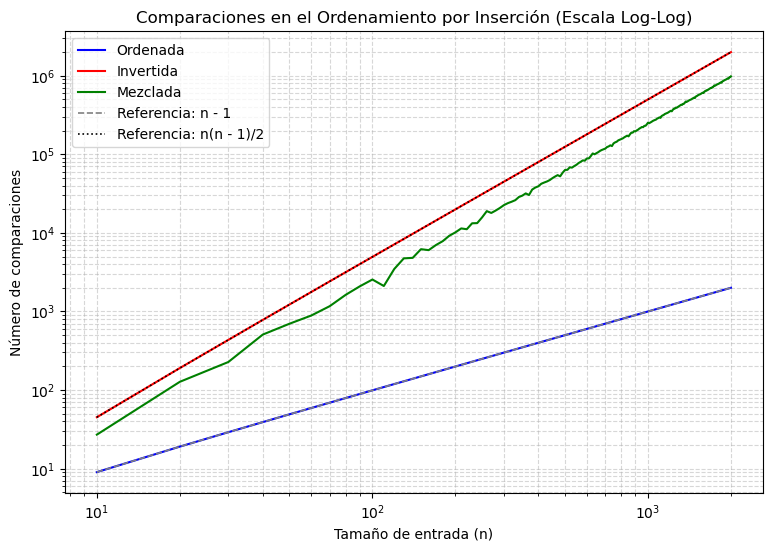

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def insercion_conteo(a):
    a = list(a)
    comparaciones = 0
    for i in range(1, len(a)):
        x = a[i]
        j = i - 1
        while j >= 0:
            comparaciones += 1
            if a[j] > x:
                a[j + 1] = a[j]
                j = j - 1
            else:
                break
        a[j + 1] = x
    return comparaciones

n_values = list(range(10, 2001, 10))
comp_ordenada = []
comp_invertida = []
comp_mezclada = []

for n in n_values:
    # Tipos de entrada según la descripción del ejercicio
    ordenada = list(range(n))
    invertida = list(range(n, 0, -1))
    mezclada = [(37 * i) % n for i in range(n)]
    
    comp_ordenada.append(insercion_conteo(ordenada))
    comp_invertida.append(insercion_conteo(invertida))
    comp_mezclada.append(insercion_conteo(mezclada))

ref_lineal = [n - 1 for n in n_values]
ref_cuadratica = [n * (n - 1) / 2 for n in n_values]

plt.figure(figsize=(9, 6))
plt.plot(n_values, comp_ordenada, label='Ordenada', color='blue', linewidth=1.5)
plt.plot(n_values, comp_invertida, label='Invertida', color='red', linewidth=1.5)
plt.plot(n_values, comp_mezclada, label='Mezclada', color='green', linewidth=1.5)
plt.plot(n_values, ref_lineal, label='Referencia: n - 1', color='gray', linestyle='--', linewidth=1.2)
plt.plot(n_values, ref_cuadratica, label='Referencia: n(n - 1)/2', color='black', linestyle=':', linewidth=1.2)

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Tamaño de entrada (n)')
plt.ylabel('Número de comparaciones')
plt.title('Comparaciones en el Ordenamiento por Inserción (Escala Log-Log)')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend(loc='upper left')

plt.savefig('insercion_comparaciones_log.png', dpi=300, bbox_inches='tight')
print("Gráfica generada y guardada exitosamente.")